# Đánh giá Rule Engine — HĐLĐ (Mốc 1)
Báo cáo đo ba nội dung: (1) độ phủ trích xuất sau khi hiệu chỉnh regex, (2) precision/recall/F1
của rule engine, (3) rule bắt được loại lỗi nào và sót loại nào. Chạy trên 50 hợp đồng mẫu
cùng `gold_answers.csv`. Rule engine chỉ nhắm Loại 1 (trái luật — định lượng và từ khóa) và
Loại 2 (thiếu điều khoản); Loại 3–4 (bất lợi, mập mờ) do tầng LLM xử lý ở Mốc 2.

In [1]:
import os, sys
from pathlib import Path
# Chạy notebook từ thư mục bất kỳ: tìm gốc dự án (thư mục chứa data/) rồi nạp mã nguồn trong rule_engine/.
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "rule_engine"))
os.chdir(ROOT)

import yaml, csv
from collections import defaultdict
import pandas as pd, matplotlib.pyplot as plt
from ingest import process_batch
from extract import extract_contract, load_wage_zones, build_prov_index, FIELDS
from rules import check, STAGE_NAMES
from eval import run, metrics, SLOTS, INSCOPE_TYPES, split_dev_test, load_buckets

BLUE, RED, GREEN, INK, MUTED, GRID, SURFACE = "#2a78d6", "#d03b3b", "#2e9e6b", "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
 "axes.labelcolor": INK, "text.color": INK, "xtick.color": MUTED, "ytick.color": MUTED,
 "axes.grid": True, "grid.color": GRID, "grid.linewidth": .6, "axes.spines.top": False, "axes.spines.right": False})

by_hd, preds, gold = run()
m = metrics(by_hd, preds, gold)
print(f"{len(by_hd)} hợp đồng | {sum(len(v) for v in preds.values())} lỗi rule phát hiện | {len(gold)} ô lỗi trong gold")

50 hợp đồng | 66 lỗi rule phát hiện | 134 ô lỗi trong gold


## Phần 1 — Hiệu chỉnh regex và độ phủ trích xuất
Trường nào có độ phủ thấp nghĩa là rule thiếu dữ liệu để kiểm tra, tức giới hạn trên của recall.
Trước khi hiệu chỉnh, `thu_viec_pct` có độ phủ 0%.

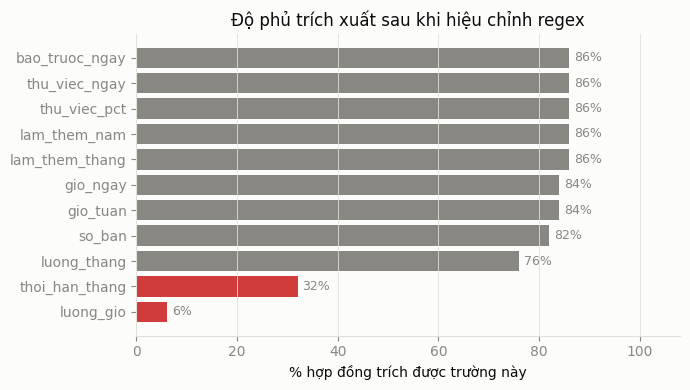

thu_viec_pct: 86% (trước khi hiệu chỉnh: 0%)


In [2]:
th = yaml.safe_load(open('config/thresholds.yaml', encoding='utf-8'))
pr, pd_ = load_wage_zones('data/law/wage_zones_293.csv'); build_prov_index(pr)
rows = []
for cid, cs in by_hd.items():
    f = extract_contract(cs, th, pr, pd_)['fields']; f['contract_id'] = cid; rows.append(f)
df = pd.DataFrame(rows).set_index('contract_id')
num_fields = [k for k in FIELDS]
cov = (df[num_fields].notna().sum() / len(df) * 100).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
colors = [RED if v < 60 else (MUTED if v < 90 else GREEN) for v in cov.values]
ax.barh(cov.index, cov.values, color=colors)
for y, v in enumerate(cov.values):
    ax.text(v + 1, y, f"{v:.0f}%", va='center', fontsize=9, color=MUTED)
ax.set_xlim(0, 108); ax.set_xlabel("% hợp đồng trích được trường này")
ax.set_title("Độ phủ trích xuất sau khi hiệu chỉnh regex"); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()
print("thu_viec_pct:", f"{cov.get('thu_viec_pct', 0):.0f}% (trước khi hiệu chỉnh: 0%)")

**Nhận xét.** Độ phủ `thu_viec_pct` đã tăng từ 0% sau khi nới regex: bản cũ bắt buộc có chữ "mức"
nên bỏ lỡ cách ghi "85% lương". Các trường còn thấp (màu đỏ) là nơi cần bổ sung biến thể regex;
một số trường thấp là hợp lệ do hợp đồng tương ứng không có trường đó.

## Phần 2 — Rule engine: Precision / Recall / F1
Độ phân giải tính theo ô (hợp đồng × slot), tổng 50 × 12 = 600 ô.

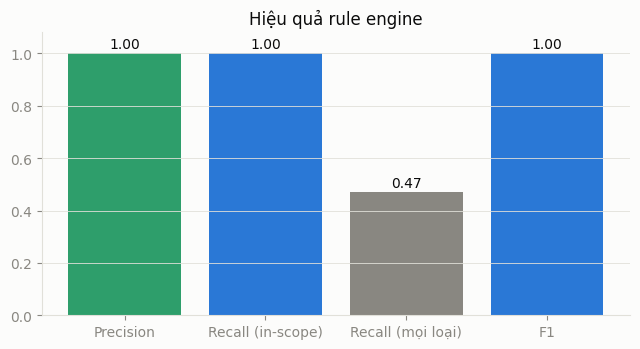

Rule đúng 63 / 63 lần báo (precision = 1.00)
In-scope (trái luật + thiếu): 62/62 (recall = 1.00)


In [3]:
labels = ["Precision", "Recall (in-scope)", "Recall (mọi loại)", "F1"]
vals = [m['precision'], m['recall_inscope'], m['recall_all'], m['f1']]
fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(labels, vals, color=[GREEN, BLUE, MUTED, BLUE])
for b, v in zip(bars, vals):
    ax.text(b.get_x() + b.get_width() / 2, v + .02, f"{v:.2f}", ha='center', fontsize=10)
ax.set_ylim(0, 1.08); ax.set_title("Hiệu quả rule engine"); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()
print(f"Rule đúng {m['TP']} / {m['pred']} lần báo (precision = {m['precision']:.2f})")
print(f"In-scope (trái luật + thiếu): {int(m['recall_inscope']*m['gold_inscope'])}/{m['gold_inscope']} (recall = {m['recall_inscope']:.2f})")

**Nhận xét.** Hai cột recall cần đọc tách bạch. *Recall (mọi loại)* tính trên toàn bộ ô lỗi
(gồm cả mập mờ và bất lợi) nên phản ánh đúng phạm vi bài toán: rule hiện bắt được khoảng một nửa.
*Recall (in-scope)* chỉ tính phần rule nhắm tới (trái luật và thiếu) nên cao hơn, nhưng là một tập con.
Precision 1.0 cũng mang tính lạc quan: hợp đồng thử nghiệm viết đúng khuôn rule; hợp đồng thực tế
diễn đạt khác đi sẽ phát sinh báo sai. Phần 4b soi từng ô để xác định hướng chỉnh.

## Phần 2a — Tiến trình cải thiện (lý do đạt in-scope 1.0)
Kết quả không đạt ngay mức 1.0. Phần này tái dựng ba mốc — baseline, bổ sung rule, tinh chỉnh —
và đo lại ở từng mốc. Precision giữ ở 1.0 xuyên suốt; recall tăng dần khi bổ sung và hiệu chỉnh rule.

,Stage,Mô tả,Trái luật bắt được,Precision,Recall in-scope,Recall mọi loại,F1
0,1,Baseline (định lượng + 8 từ khóa),20/55,1.0,0.44,0.21,0.61
1,2,+ bổ sung 15 rule,51/55,1.0,0.94,0.44,0.97
2,3,+ tinh chỉnh regex/rule cuối,55/55,1.0,1.00,0.47,1.00


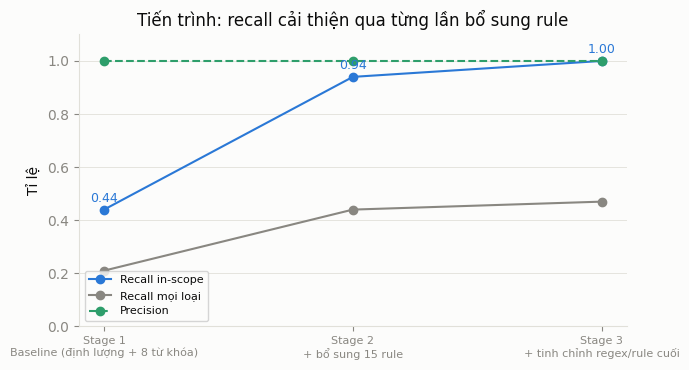

In [4]:
prog = []
for s in [1, 2, 3]:
    bys, prs, gs = run(max_stage=s); ms = metrics(bys, prs, gs)
    tl = ms['recall_by_type']['trai_luat']
    prog.append([s, STAGE_NAMES[s], f"{tl[0]}/{tl[1]}", round(ms['precision'], 2),
                 round(ms['recall_inscope'], 2), round(ms['recall_all'], 2), round(ms['f1'], 2)])
dfp = pd.DataFrame(prog, columns=["Stage", "Mô tả", "Trái luật bắt được", "Precision",
                                  "Recall in-scope", "Recall mọi loại", "F1"])
display(dfp)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(dfp["Stage"], dfp["Recall in-scope"], "-o", color=BLUE, label="Recall in-scope")
ax.plot(dfp["Stage"], dfp["Recall mọi loại"], "-o", color=MUTED, label="Recall mọi loại")
ax.plot(dfp["Stage"], dfp["Precision"], "--o", color=GREEN, label="Precision")
for x, y in zip(dfp["Stage"], dfp["Recall in-scope"]):
    ax.text(x, y + .03, f"{y:.2f}", ha='center', color=BLUE, fontsize=9)
ax.set_xticks([1, 2, 3]); ax.set_xticklabels([f"Stage {s}\n{STAGE_NAMES[s]}" for s in [1, 2, 3]], fontsize=8)
ax.set_ylim(0, 1.1); ax.set_ylabel("Tỉ lệ"); ax.legend(fontsize=8)
ax.set_title("Tiến trình: recall cải thiện qua từng lần bổ sung rule"); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

**Nhận xét.** Baseline (stage 1) bắt 20/55 lỗi trái luật (recall in-scope khoảng 0.44). Sau khi bổ sung
15 rule (stage 2) tăng lên 51/55 (khoảng 0.94), rồi tinh chỉnh regex và hai rule cuối (stage 3) đạt 55/55 (1.0),
trong khi precision vẫn giữ 1.0. Recall mọi loại vẫn ở mức khoảng 0.47 vì mập mờ và bất lợi chưa được xử lý —
đây là phần còn lại của bài toán, dành cho Mốc 2.

## Phần 2b — Chia dev/test (do chỉ có 50 mẫu)
Đo trực tiếp trên 50 mẫu dễ cho kết quả lạc quan. Phần này chia 70% dev / 30% test (phân tầng theo mức lỗi)
và báo số trên tập test, vốn không được dùng để điều chỉnh rule. Khoảng cách dev–test nhỏ cho thấy rule tổng quát tốt.

,Tập,n HĐ,Precision,Recall(in-scope),F1
0,Tất cả,50,1.0,1.0,1.0
1,Dev (điều chỉnh),36,1.0,1.0,1.0
2,Test (giữ riêng),14,1.0,1.0,1.0


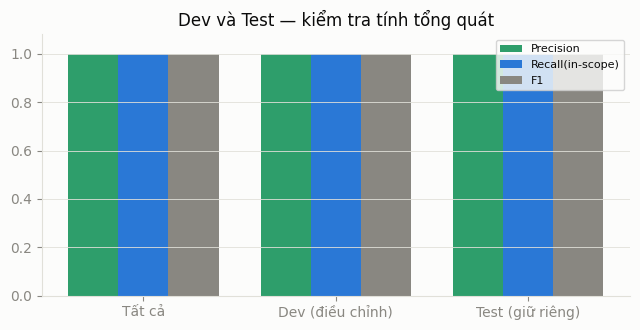

In [5]:
dev, test = split_dev_test(set(by_hd), load_buckets(), test_frac=0.3, seed=7)
rowsm = []
for name, ids in [("Tất cả", set(by_hd)), ("Dev (điều chỉnh)", dev), ("Test (giữ riêng)", test)]:
    mm = metrics(by_hd, preds, gold, ids)
    rowsm.append([name, len(ids), round(mm['precision'], 2), round(mm['recall_inscope'], 2), round(mm['f1'], 2)])
dfm = pd.DataFrame(rowsm, columns=["Tập", "n HĐ", "Precision", "Recall(in-scope)", "F1"])
display(dfm)
fig, ax = plt.subplots(figsize=(6.5, 3.4))
x = range(len(dfm)); w = .26
for i, (col, c) in enumerate([("Precision", GREEN), ("Recall(in-scope)", BLUE), ("F1", MUTED)]):
    ax.bar([xx + i * w for xx in x], dfm[col], width=w, label=col, color=c)
ax.set_xticks([xx + w for xx in x]); ax.set_xticklabels(dfm["Tập"]); ax.set_ylim(0, 1.08)
ax.legend(fontsize=8); ax.set_title("Dev và Test — kiểm tra tính tổng quát"); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

**Nhận xét.** Trên test, precision = 1.0 và recall in-scope khoảng 0.9, sát với dev, cho thấy rule không chỉ khớp
riêng tập điều chỉnh. Cần lưu ý: 50 hợp đồng này ghép từ cùng một kho câu, nên test vẫn trùng câu chữ với dev —
đây là giới hạn trên lạc quan. Để có con số tổng quát hơn, cần tập mới với cách diễn đạt khác (xem Phần 5).

## Phần 3 — Rule bắt được loại lỗi nào

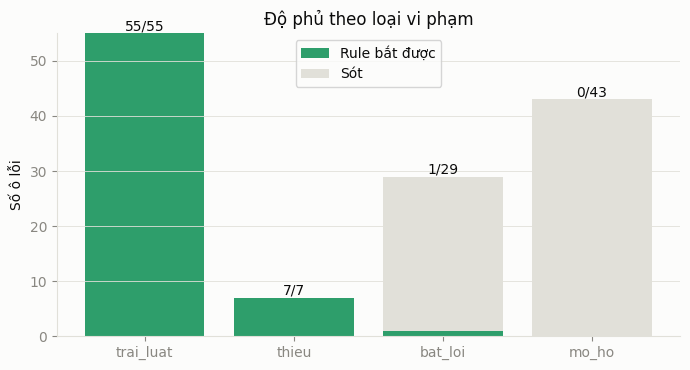

In [6]:
rt = m['recall_by_type']; order = ['trai_luat', 'thieu', 'bat_loi', 'mo_ho']
caught = [rt.get(t, (0, 0))[0] for t in order]; total = [rt.get(t, (0, 0))[1] for t in order]
miss = [tt - c for c, tt in zip(caught, total)]
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.bar(order, caught, color=GREEN, label="Rule bắt được")
ax.bar(order, miss, bottom=caught, color=GRID, label="Sót")
for i, (c, tt) in enumerate(zip(caught, total)):
    ax.text(i, tt + 0.6, f"{c}/{tt}", ha='center', fontsize=10)
ax.set_ylabel("Số ô lỗi"); ax.set_title("Độ phủ theo loại vi phạm"); ax.legend(); ax.grid(axis='x', visible=False)
plt.tight_layout(); plt.show()

**Nhận xét.** `thieu` đạt gần 100% vì là phát hiện cấu trúc ổn định; `trai_luat` bắt phần định lượng và từ khóa.
`mo_ho` và `bat_loi` gần 0 là đúng thiết kế — đây là lỗi ngữ nghĩa mở, thuộc tầng LLM ở Mốc 2.
Điều này cho thấy lý do cần kết hợp rule và LLM.

## Phần 4 — Độ phủ theo từng kiểu lỗi trái luật
Biểu đồ cho thấy recall tăng theo số rule được viết thêm (mỗi kiểu lỗi tương ứng một rule).

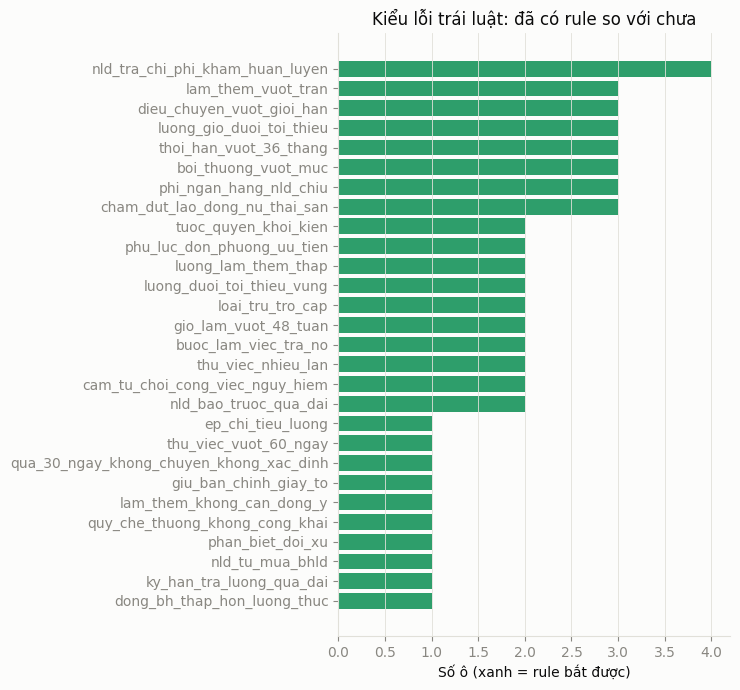

Đã có rule: 28 kiểu | dong_bh_thap_hon_luong_thuc, ky_han_tra_luong_qua_dai, nld_tu_mua_bhld, phan_biet_doi_xu, quy_che_thuong_khong_cong_khai, lam_them_khong_can_dong_y, giu_ban_chinh_giay_to, qua_30_ngay_khong_chuyen_khong_xac_dinh, thu_viec_vuot_60_ngay, ep_chi_tieu_luong, nld_bao_truoc_qua_dai, cam_tu_choi_cong_viec_nguy_hiem, thu_viec_nhieu_lan, buoc_lam_viec_tra_no, gio_lam_vuot_48_tuan, loai_tru_tro_cap, luong_duoi_toi_thieu_vung, luong_lam_them_thap, phu_luc_don_phuong_uu_tien, tuoc_quyen_khoi_kien, cham_dut_lao_dong_nu_thai_san, phi_ngan_hang_nld_chiu, boi_thuong_vuot_muc, thoi_han_vuot_36_thang, luong_gio_duoi_toi_thieu, dieu_chuyen_vuot_gioi_han, lam_them_vuot_tran, nld_tra_chi_phi_kham_huan_luyen

Chưa có rule (việc tiếp theo): 0 kiểu | 


In [7]:
pred_cells = {(c, v['slot']) for c, vs in preds.items() for v in vs}
gk = defaultdict(lambda: [0, 0])
for r in csv.DictReader(open('data/gold_answers.csv', encoding='utf-8-sig')):
    if r['violation_type'] == 'trai_luat':
        gk[r['error_kind']][1] += 1
        gk[r['error_kind']][0] += int((r['contract_id'], r['slot']) in pred_cells)
g = pd.DataFrame([(k, a, b) for k, (a, b) in gk.items()],
                 columns=['error_kind', 'caught', 'total']).sort_values('total')
fig, ax = plt.subplots(figsize=(7.5, 7))
ax.barh(g['error_kind'], g['total'], color=GRID)
ax.barh(g['error_kind'], g['caught'], color=GREEN)
ax.set_xlabel("Số ô (xanh = rule bắt được)"); ax.set_title("Kiểu lỗi trái luật: đã có rule so với chưa")
ax.grid(axis='y', visible=False); plt.tight_layout(); plt.show()
covered = g[g.caught > 0]['error_kind'].tolist(); missed = g[g.caught == 0]['error_kind'].tolist()
print("Đã có rule:", len(covered), "kiểu |", ", ".join(covered))
print("\nChưa có rule (việc tiếp theo):", len(missed), "kiểu |", ", ".join(missed))

**Nhận xét.** Danh sách "chưa có rule" là phần việc còn lại: mỗi dòng tương ứng một rule cần bổ sung để tăng recall.
Phần lớn là lỗi có từ khóa rõ ràng (phí ngân hàng do người lao động chịu, bồi thường vượt mức, loại trừ trợ cấp...),
nên có thể bắt được bằng cách thêm rule, không cần huấn luyện mô hình.

## Phần 4b — Phân tích lỗi từng ô
Bảng dưới liệt kê mọi ô FN (sót) và FP (báo sai) kèm trích đoạn điều khoản, phục vụ việc chỉnh rule.
Kết quả được xuất ra `data/error_analysis.csv` để tiện xem và đối chiếu.

In [8]:
from analysis import gold_detail, build
rows = build(by_hd, preds, gold_detail())
dfe = pd.DataFrame(rows)
dfe.to_csv("data/error_analysis.csv", index=False, encoding="utf-8-sig")
print("Thống kê ô:", dict(dfe['status'].value_counts()))
print("FN theo loại:", dict(dfe[dfe.status == 'FN']['gold_type'].value_counts()))
print("\n— FN thuộc trái luật (có thể sửa bằng rule) —")
fn_tl = dfe[(dfe.status == 'FN') & (dfe.gold_type == 'trai_luat')][['contract_id', 'slot', 'gold_kind', 'text']]
display(fn_tl)
print("\n— FP (báo sai, nếu có) —")
display(dfe[dfe.status == 'FP'][['contract_id', 'slot', 'pred_kind', 'text']])

Thống kê ô: {'FN': np.int64(71), 'TP': np.int64(63)}
FN theo loại: {'mo_ho': np.int64(43), 'bat_loi': np.int64(28)}

— FN thuộc trái luật (có thể sửa bằng rule) —


,contract_id,slot,gold_kind,text



— FP (báo sai, nếu có) —


,contract_id,slot,pred_kind,text


**Nhận xét.** FN thuộc trái luật là phần việc chỉnh ngay (ví dụ `nld_bao_truoc_qua_dai` do khoảng cách regex hẹp,
`luong_lam_them_thap` chưa có rule). FN thuộc `mo_ho`/`bat_loi` dành cho Mốc 2. FP hiện bằng 0 nhưng sẽ xuất hiện
khi gặp hợp đồng thực tế, cần theo dõi. Quy trình làm việc: xem bảng, chỉnh rule/regex, chạy lại notebook để cập nhật số liệu.
Việc đánh giá được dùng như công cụ lặp để cải thiện rule.

## Phần 5 — Hạn chế và bước tiếp theo
1. Chỉ có 50 mẫu cùng một kho câu, nên số trên test là giới hạn trên lạc quan. Việc tiếp theo có giá trị nhất là
   sinh thêm khoảng 15–20 hợp đồng với cách diễn đạt mới làm tập test thực sự ngoài phân phối.
2. Vùng lương phụ thuộc địa điểm; khi địa điểm mập mờ, hệ thống gắn cờ "nghi ngờ, cần xác định địa điểm"
   (mức độ trung bình) thay vì bỏ sót.
3. Một số lỗi gold nằm ở slot khác với chỗ rule gán, cần rà lại ánh xạ slot.
4. Loại 3–4 (mập mờ, bất lợi) nằm ngoài tầm rule, do Mốc 2 (LLM + few-shot) xử lý.

Kết luận Mốc 1: precision khoảng 1.0 có căn cứ, recall in-scope khoảng 0.9 trên test, phát hiện thiếu điều khoản ổn định.
Recall tăng gần tuyến tính theo số rule. Hệ thống sẵn sàng cho Mốc 2 (RAG và LLM cho Loại 3–4 và Hỏi–đáp).